In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
%matplotlib inline
import seaborn as sns 


In [2]:
data = pd.read_csv(r"D:\eda\airline_eda\airlines_flights_data.csv")

In [3]:
data.head()

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


##DF LOC AND ILOC 

In [41]:
#data.loc[0:5, "airline":"stops"]

LOC

In [ ]:
#data.iloc[1:3 ,2: 4]

## Query 

In [50]:
data.query("source_city == 'Mumbai' and airline == 'AirAsia' and price > 6337")

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
43048,43048,AirAsia,I5-631,Mumbai,Morning,one,Evening,Delhi,Economy,11.75,1,8452
43067,43067,AirAsia,I5-942,Mumbai,Afternoon,one,Late_Night,Delhi,Economy,12.25,1,13685
43151,43151,AirAsia,I5-942,Mumbai,Afternoon,one,Night,Delhi,Economy,9.17,2,7251
43152,43152,AirAsia,I5-942,Mumbai,Afternoon,one,Late_Night,Delhi,Economy,12.25,2,7251
43276,43276,AirAsia,I5-942,Mumbai,Afternoon,one,Night,Delhi,Economy,9.17,3,7251
...,...,...,...,...,...,...,...,...,...,...,...,...
78080,78080,AirAsia,I5-941,Mumbai,Early_Morning,one,Afternoon,Chennai,Economy,7.50,7,13818
78181,78181,AirAsia,I5-941,Mumbai,Early_Morning,one,Afternoon,Chennai,Economy,7.50,8,11129
78363,78363,AirAsia,I5-941,Mumbai,Early_Morning,one,Afternoon,Chennai,Economy,7.50,9,23358
78754,78754,AirAsia,I5-941,Mumbai,Early_Morning,one,Afternoon,Chennai,Economy,7.50,12,11129


In [43]:
data.query("source_city == 'Delhi' and price < 6000")

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...,...,...
42995,42995,Vistara,UK-955,Delhi,Evening,one,Morning,Chennai,Economy,15.08,49,5742
42996,42996,Vistara,UK-977,Delhi,Evening,one,Morning,Chennai,Economy,16.92,49,5742
42997,42997,Indigo,6E-963,Delhi,Evening,one,Late_Night,Chennai,Economy,4.92,49,5528
42998,42998,Indigo,6E-963,Delhi,Evening,one,Early_Morning,Chennai,Economy,10.42,49,5528


## ISIN

In [56]:
data[data["airline"].isin(["AirAsia", "Indigo"])]

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
12,12,Indigo,6E-5001,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.17,1,5955
13,13,Indigo,6E-6202,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.17,1,5955
14,14,Indigo,6E-549,Delhi,Afternoon,zero,Evening,Mumbai,Economy,2.25,1,5955
15,15,Indigo,6E-6278,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...,...,...
206614,206614,Indigo,6E-6215,Chennai,Evening,zero,Evening,Hyderabad,Economy,1.33,49,1551
206615,206615,Indigo,6.00E-193,Chennai,Evening,zero,Night,Hyderabad,Economy,1.33,49,1551
206616,206616,AirAsia,I5-1229,Chennai,Night,one,Morning,Hyderabad,Economy,9.25,49,1550
206617,206617,AirAsia,I5-2462,Chennai,Night,one,Morning,Hyderabad,Economy,10.17,49,1550


GroupBy 

In [62]:
data.groupby('airline')['price'].mean()
data.groupby(['source_city', 'destination_city', 'departure_time']).agg({
    'price': ['mean', 'min', 'max', 'count', 'nunique'],
    'duration': ['mean', 'max']
})

price                      \
                                                     mean   min     max count   
source_city destination_city departure_time                                     
Bangalore   Chennai          Afternoon       23446.957647  1603   77790   425   
                             Early_Morning   24477.709419  1603   73948  1497   
                             Evening         21531.741822  1603   65548  1987   
                             Late_Night      26375.000000  5435   44682    36   
                             Morning         22926.686013  1604   82320  1723   
...                                                   ...   ...     ...   ...   
Mumbai      Kolkata          Early_Morning   20762.161323  2835  100909  2932   
                             Evening         24212.760663  2835   97549  2837   
                             Late_Night       5342.825000  2835   14526    80   
                             Morning         23796.101871  2835   98904  1924   
                             Night           23381.924186  2835   95421  2150   

                                                      duration         
                                            nunique       mean    max  
source_city destination_city departure_time                            
Bangalore   Chennai          Afternoon           98  15.054659  40.75  
                             Early_Morning      150  13.398918  40.67  
                             Evening            181  16.024464  47.75  
                             Late_Night           5  18.166667  20.50  
                             Morning            179  13.010133  35.75  
...                                             ...        ...    ...  
Mumbai      Kolkata          Early_Morning      363  11.322500  37.58  
                             Evening            348  16.196729  30.67  
                             Late_Night          16   5.688000   8.33  
                             Morning            377  11.236055  34.08  
                             Night              143  13.635753  25.83  

[168 rows x 7 columns]

Rename a column 
# Convert all column names to lowercase
df.columns = df.columns.str.lower()

# Replace spaces with underscores in all column names
df.columns = df.columns.str.replace(" ", "_")

import pandas as pd

df = pd.DataFrame({"A": [1, 2], "B": [3, 4], "C": [5, 6]})

# Rename columns 'A' and 'B'
df = df.rename(columns={"A": "Alpha", "B": "Beta"})



In [15]:
data = data.rename(columns = {"index":"Index", "price":" Price"})
data

,Index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,Price,price_per_hour
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953,2743.317972
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953,2554.935622
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956,2744.700461
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955,2646.666667
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955,2555.793991
...,...,...,...,...,...,...,...,...,...,...,...,...,...
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265,6871.527778
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105,7399.712092
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099,5719.378163
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585,8158.500000


In [ ]:
data.columns.str.replace("_", " ")
data


TypeError: StringMethods.replace() got an unexpected keyword argument 'inplace'

## Transformation

In [ ]:
data['price_per_hour'] = data['price']/data['duration']

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price,price_per_hour
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953,2743.317972
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953,2554.935622
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956,2744.700461
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955,2646.666667
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955,2555.793991
...,...,...,...,...,...,...,...,...,...,...,...,...,...
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265,6871.527778
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105,7399.712092
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099,5719.378163
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585,8158.500000


## Cleaning Data Set

In [ ]:
cleanData = data.drop(columns=["price","class"])
cleanData

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,duration,days_left
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,2.17,1
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,2.33,1
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,2.17,1
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,2.25,1
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,2.33,1
...,...,...,...,...,...,...,...,...,...
300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,10.08,49
300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,10.42,49
300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,13.83,49
300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,10.00,49


In [ ]:
# remove the index column 

data.drop(columns = "index", inplace= True)


In [ ]:
#get some Info about the dataset

data.info()



<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  str    
 1   flight            300153 non-null  str    
 2   source_city       300153 non-null  str    
 3   departure_time    300153 non-null  str    
 4   stops             300153 non-null  str    
 5   arrival_time      300153 non-null  str    
 6   destination_city  300153 non-null  str    
 7   class             300153 non-null  str    
 8   duration          300153 non-null  float64
 9   days_left         300153 non-null  int64  
 10  price             300153 non-null  int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 25.2 MB


In [ ]:
data.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [ ]:
#Get statistical summary about  the dataset
data.describe()

,duration,days_left,price
count,300153.000000,300153.000000,300153.000000
mean,12.221021,26.004751,20889.660523
std,7.191997,13.561004,22697.767366
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4783.000000
50%,11.250000,26.000000,7425.000000
75%,16.170000,38.000000,42521.000000
max,49.830000,49.000000,123071.000000


In [ ]:
data[data['duration'] == 49.8300]

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
193889,Air_India,AI-672,Chennai,Evening,two_or_more,Evening,Bangalore,Economy,49.83,2,23891
194359,Air_India,AI-672,Chennai,Evening,one,Evening,Bangalore,Economy,49.83,9,17538


In [ ]:
data[data['duration'] == 0.8300000]

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
115869,Indigo,6E-357,Bangalore,Night,zero,Night,Chennai,Economy,0.83,6,3498
115943,Indigo,6E-357,Bangalore,Night,zero,Night,Chennai,Economy,0.83,7,3498
116010,Indigo,6E-357,Bangalore,Night,zero,Night,Chennai,Economy,0.83,8,3498
116081,Indigo,6E-357,Bangalore,Night,zero,Night,Chennai,Economy,0.83,9,3498
116163,Indigo,6E-357,Bangalore,Night,zero,Night,Chennai,Economy,0.83,10,3498
116236,Indigo,6E-357,Bangalore,Night,zero,Night,Chennai,Economy,0.83,11,3498
116322,Indigo,6E-357,Bangalore,Night,zero,Night,Chennai,Economy,0.83,12,3498
116411,Indigo,6E-357,Bangalore,Night,zero,Night,Chennai,Economy,0.83,13,3498
116496,Indigo,6E-357,Bangalore,Night,zero,Night,Chennai,Economy,0.83,14,3498
116656,Indigo,6E-357,Bangalore,Night,zero,Night,Chennai,Economy,0.83,16,1924


In [ ]:
## max price
data[data['price'] == 123071.00000]

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
261377,Vistara,UK-772,Kolkata,Morning,one,Night,Delhi,Business,13.5,3,123071


In [ ]:
#minimum price
data[data['price'] == 123071.00000]

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
261377,Vistara,UK-772,Kolkata,Morning,one,Night,Delhi,Business,13.5,3,123071


In [ ]:
data.isnull.sum()

AttributeError: 'function' object has no attribute 'sum'

Q1. what are the airlines in the  dataset, accompained  by their  frequencies?

In [ ]:
data['airline'].nunique()

6

In [ ]:
data['airline'].value_counts()

airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64

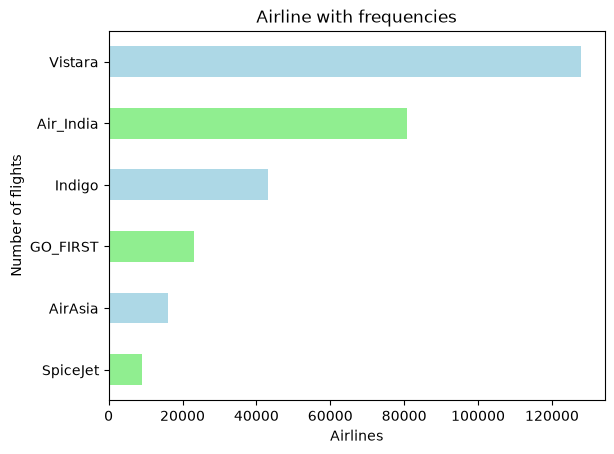

In [ ]:
data['airline'].value_counts(ascending= True).plot.barh(color= ['lightgreen','lightblue'])
plt.title("Airline with frequencies")
plt.xlabel("Airlines")
plt.ylabel("Number of flights")
plt.show()

In [ ]:
#Showing the departure Time  for the  flights
data['departure_time '].value_counts()

KeyError: 'departure_time '

In [ ]:
#Showing the departure Time  for the  flights
data['arrival_time '].value_counts()

In [ ]:
plt.figure(figsize= (16,4))
plt.subplot(1,2,1)

plt.bar(data['departure_time '].value_counts().index, data['departure_time '].value_counts(), color=['r','b'])

plt.title("Depature Time")
plt.xlabel("Time")
plt.ylabel("Freq")
plt.show()


plt.subplot(1,2,2)

plt.bar(data['arrivel_time '].value_counts().index, data['arrival_time '].value_counts(), color=['r','b'])

plt.title("Arrival Time")
plt.xlabel("Time")
plt.ylabel("Freq")
plt.show()

Q Show the bar graph representing Source city and destination  city.



In [ ]:
plt.figure(figsize=(16,4))

plt.subplot(1,2,1)

plt.bar(data['source_city'].value_counts().index, data['source_city'].value_counts(), color=['r','b'])

plt.title("Source City")
plt.xlabel("City")
plt.ylabel("No 0f flights")
plt.show()

plt.subplot(1,2,2)

plt.bar(data['destination_city'].value_counts().index, data['destination_city'].value_counts(), color=['r','b'], hue = 'class')

plt.title("Destination City")
plt.xlabel("City")
plt.ylabel("No 0f flights")
plt.show()




Does the price varies with airline ?

In [ ]:
data.groupby('airline')['price'].mean()

In [ ]:
sns.catplot(x = 'airline' , y = 'price', kind = 'bar',palete = 'rocket', data = data)

Q5 Does ticket price change based  on the  deprature time and arrival  time ?

In [ ]:
#Checking the mean ticket price onthe Departure Time.
data.groupby('departure_time')['price'].mean()

In [ ]:
#Checking the mean ticket price onthe Departure Time.
data.groupby('departure_time')['price'].mean()

In [ ]:
sns.catplot(x = 'departure_time', y = 'price', kind = 'bar', data =data)

plt.show()

In [ ]:
sns.relplot(x='arrival_time' ,  y = 'price' , data =data , col = 'departure_time', kind = 'line')

Q 6 . How the price changes with change in Source and Destiantion ?

In [ ]:
#checking the mean ticket price for each source city

data.groupby('source_city')['price'].mean()

In [ ]:
sns.replot(x= 'destination_city' , y = 'price', data = data, col ='source_city', kind='line' )

## Apply Function 

In [6]:
data.head(2)

data.price.value_counts()

price
54608    1445
2339     1442
54684    1390
60978    1383
60508    1230
         ... 
75395       1
74664       1
79211       1
91531       1
74731       1
Name: count, Length: 12157, dtype: int64

In [8]:



def price_categorization(p):
    if (p > 2000 and p < 5000 ):
        return 'cheap'
    elif ( p > 5000  and p < 7000):
        return 'moderate'
    else:
        return 'expensive'

data['price_category'] = data['price'].apply(price_categorization)

data
    
    

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price,price_category
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953,moderate
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953,moderate
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956,moderate
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955,moderate
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955,moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265,expensive
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105,expensive
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099,expensive
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585,expensive


In [9]:
data['price_category'].value_counts()

price_category
expensive    162184
cheap         76340
moderate      61629
Name: count, dtype: int64